# AMC 2026 – Round 3 · Strategy A: macro regimes
Matterhorn Capital Management · group 3

**What this notebook does.** It classifies each month into one of four macro regimes from **growth** and **inflation**, finds which asset class did best in each regime using **only the months known at the time**, and tells us which asset the strategy holds from the close of **27 November 2026**.

**Our rule (chosen before running any backtest):**
- **Growth: CFNAI** (Chicago Fed National Activity Index, 85 indicators of production, jobs, consumption and orders; 0 = growth at its long-run trend), as in the Class 7 slides. Growth is *up* when its 3-month average is above 0.
- **Inflation: headline CPI year on year**, *rising* when it is above its value 12 months earlier (TA's rule; the Class 7 median of the change is −0.01 pp, i.e. zero).
- **Timing:** at the end of month *t* we use the data of month *t − 1* (CPI and CFNAI are published 2–4 weeks after the month ends), and we earn the return of month *t + 1*.

Why CFNAI and not the ISM PMI (the TA's choice): it covers the whole economy, not only manufacturing (about 10% of GDP); its zero line is trend growth by construction, so the threshold uses no future data; and in a supply shock the PMI can rise because deliveries slow down. Its costs: CFNAI is revised (Bloomberg gives today's revised history, a small look-ahead in the backtest), and today it is close to zero.

**Inputs:** `r7_macro.csv`, `r7_assets.csv`, `r7_rf_long.csv` (notebook 01) and `r7_extra.csv` (notebook 01, sheet *Extra* of our Bloomberg template: CFNAI and core CPI). Until `r7_extra.csv` exists, only the TA's PMI version runs.

## 0. Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", "{:.3f}".format)

# Our Round 1 SAA (data/holdings.json): the benchmark of every deviation
W_SAA = pd.Series({"VTI": 0.1090, "VEA": 0.1024, "IEMG": 0.1023, "BND": 0.1333,
                   "BNDX": 0.1648, "TIP": 0.1526, "GLD": 0.1115, "BCI": 0.1240})
START, SPLIT = "2002-01-31", "2013-12-31"   # Class 4: choose on 2002-2013, check once on 2014-2026
MIN_N    = 24                                # months in a regime before we trust a Sharpe Ratio
DISCOUNT = 0.5                               # Class 4: realistic Sharpe = backtest Sharpe x 0.5
ORDER = ["Goldilocks", "Overheating", "Stagflation", "Slowdown"]
COL   = {"Goldilocks": "#1baf7a", "Overheating": "#eda100", "Stagflation": "#eb6834", "Slowdown": "#2a78d6"}

# The trials, fixed before running (Class 4: every one is reported): growth series, threshold, inflation series
TRIALS = {
    "T1 TA: PMI > 50":               ("PMI", 50.0, "CPI_yoy"),
    "T2 main: CFNAI 3m avg > 0":     ("CFNAI_MA3", 0.0, "CPI_yoy"),
    "T3 professor: CFNAI 12m avg > 0": ("CFNAI_12M", 0.0, "CPI_yoy"),
}
MAIN = "T2 main: CFNAI 3m avg > 0"


def stats(r, bench):
    # Class 2 / Class 4 measures (as in TA session 6); r and bench are monthly EXCESS returns
    T = len(r) / 12
    if r.equals(bench):                                   # the benchmark against itself
        beta, a, ir = 1.0, 0.0, np.nan
    else:
        beta, a = np.polyfit(bench, r, 1)
        eps = r - a - beta * bench
        ir = a * 12 / (eps.std() * np.sqrt(12)) if eps.std() > 0 else np.nan
    wealth = (1 + r).cumprod()
    return pd.Series({"months": len(r), "mean": r.mean() * 12, "vol": r.std() * np.sqrt(12),
                      "Sharpe": r.mean() / r.std() * np.sqrt(12), "Sharpe x 0.5": r.mean() / r.std() * np.sqrt(12) * DISCOUNT,
                      "max drawdown": (wealth / wealth.cummax() - 1).min(), "skewness": r.skew(),
                      "beta": beta, "alpha": a * 12, "t(alpha)": ir * np.sqrt(T)})

## 1. Data
Macro series are labelled by the month they describe. The October 2025 and October 2026 CPI year-on-year rates were never published (the 2025 government shutdown): we carry the previous month forward, as Bloomberg's `Fill=P` does.

In [2]:
macro  = pd.read_csv("r7_macro.csv", index_col=0, parse_dates=True)
assets = pd.read_csv("r7_assets.csv", index_col=0, parse_dates=True)
rf     = pd.read_csv("r7_rf_long.csv", index_col=0, parse_dates=True)["rf"]

X = macro[["PMI", "CPI_yoy"]].copy()
for f in ("r7_extra.csv", "cfnai.csv"):                 # Bloomberg (Extra sheet), or a Chicago Fed download
    if Path(f).exists():
        extra = pd.read_csv(f, index_col=0, parse_dates=True)
        extra.index = extra.index + pd.offsets.MonthEnd(0)
        if "CFNAI" in extra:
            X = X.join(extra[["CFNAI"]], how="outer")
            print(f"CFNAI from {f}: {extra['CFNAI'].first_valid_index():%b %Y} - {extra['CFNAI'].last_valid_index():%b %Y}")
            break
HAS_CFNAI = "CFNAI" in X
if HAS_CFNAI:
    X["CFNAI_MA3"] = X["CFNAI"].rolling(3).mean()
    X["CFNAI_12M"] = X["CFNAI"].rolling(12).mean()
else:
    print("CFNAI not available yet: refresh the Extra sheet of the Bloomberg template and run notebook 01 "
          "(it writes r7_extra.csv). Only trial T1 runs below.")
X["CPI_yoy"] = X["CPI_yoy"].ffill()

X = X.loc[:"2026-10-31"]                                # a November row from the refresh only repeats October (Fill=P): drop it
# one more row: the trade month (November 2026), whose regime uses the October data known on 27 November
X = X.reindex(X.index.append(pd.DatetimeIndex([X.index.max() + pd.offsets.MonthEnd(1)])))
Re = assets.pct_change(fill_method=None).sub(rf, axis=0)          # monthly excess returns
Re = Re.rename(columns={"DBC": "BCI"})       # notebook 01 names BCOMTR "DBC": it is the index our BCI tracks
Re = Re.loc[:"2026-10-31"]                   # no partial November return in the backtest
SAA_OK = set(W_SAA.index) <= set(Re.columns)
CAND = list(W_SAA.index) if SAA_OK else list(Re.columns)          # the asset classes the strategy can hold
print(f"Assets: {CAND} ({Re.index.min():%b %Y} - {Re.index.max():%b %Y})")
print("Benchmark:", "our SAA" if SAA_OK else "equal weight of the assets above (our SAA proxies are not in r7_assets.csv yet)")
X.tail(4)

CFNAI from r7_extra.csv: Dec 1989 - Oct 2026
Assets: ['VTI', 'VEA', 'IEMG', 'BND', 'BNDX', 'TIP', 'GLD', 'BCI'] (Dec 1989 - Oct 2026)
Benchmark: our SAA


,PMI,CPI_yoy,CFNAI,CFNAI_MA3,CFNAI_12M
2026-08-31,54.600,3.400,-0.130,0.010,-0.085
2026-09-30,54.500,3.700,0.050,0.017,-0.055
2026-10-31,55.500,3.700,-0.060,-0.047,-0.019
2026-11-30,NaN,NaN,NaN,NaN,NaN


## 2. The regimes
Growth *up* if the growth series is above its threshold; inflation *rising* if CPI y/y is above its value 12 months earlier. Each month uses the data of the month before.

In [3]:
def regimes(g_col, g_thr, i_col):
    sig = X[[g_col, i_col]].shift(1)                                   # known at the end of month t
    g = sig[g_col] > g_thr
    i = sig[i_col] > sig[i_col].shift(12)
    known = sig[g_col].notna() & sig[i_col].shift(12).notna()
    lab = np.select([g & ~i, g & i, ~g & i, ~g & ~i], ORDER, "?")
    return pd.Series(lab, index=X.index)[known]

RUN = {k: v for k, v in TRIALS.items() if HAS_CFNAI or v[0] == "PMI"}
REG = {k: regimes(*v) for k, v in RUN.items()}
today = X.index.max()
rows = []
for k, (g_col, g_thr, i_col) in RUN.items():
    gv, i_now, i_12 = X[g_col].shift(1).loc[today], X[i_col].shift(1).loc[today], X[i_col].shift(13).loc[today]
    rows.append({"trial": k, "growth": f"{g_col} {gv:.2f} vs {g_thr:g}", "growth up": gv > g_thr,
                 "inflation": f"CPI y/y {i_now:.1f}% vs {i_12:.1f}% a year earlier", "rising": i_now > i_12,
                 "regime from 27 Nov": REG[k].loc[today]})
print(f"Regime for the trade month ({today:%B %Y}), from the data of {today - pd.offsets.MonthEnd(1):%B %Y}:")
pd.DataFrame(rows).set_index("trial")

Regime for the trade month (November 2026), from the data of October 2026:


,growth,growth up,inflation,rising,regime from 27 Nov
trial,,,,,
T1 TA: PMI > 50,PMI 55.50 vs 50,True,CPI y/y 3.7% vs 3.0% a year earlier,True,Overheating
T2 main: CFNAI 3m avg > 0,CFNAI_MA3 -0.05 vs 0,False,CPI y/y 3.7% vs 3.0% a year earlier,True,Stagflation
T3 professor: CFNAI 12m avg > 0,CFNAI_12M -0.02 vs 0,False,CPI y/y 3.7% vs 3.0% a year earlier,True,Stagflation


Months in each regime, 2002 - Nov 2026:


,T1 TA: PMI > 50,T2 main: CFNAI 3m avg > 0,T3 professor: CFNAI 12m avg > 0
Goldilocks,92,44,34
Overheating,127,81,71
Stagflation,21,67,77
Slowdown,59,107,117


T2 main: CFNAI 3m avg > 0: same regime as the TA's rule in 67% of the months
T3 professor: CFNAI 12m avg > 0: same regime as the TA's rule in 62% of the months


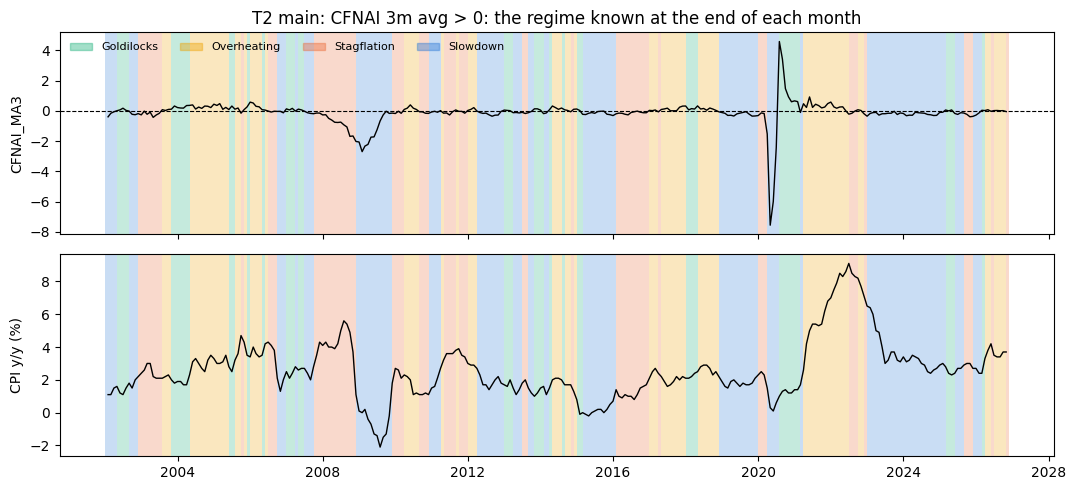

In [4]:
counts = pd.DataFrame({k: r.loc[START:].value_counts() for k, r in REG.items()}).reindex(ORDER).fillna(0).astype(int)
print(f"Months in each regime, {START[:4]} - {today:%b %Y}:")
display(counts)
if len(REG) > 1:
    base = REG["T1 TA: PMI > 50"].loc[START:]
    for k, r in REG.items():
        if k != "T1 TA: PMI > 50":
            common = base.index.intersection(r.index)
            print(f"{k}: same regime as the TA's rule in {np.mean(base[common] == r[common]):.0%} of the months")

k0 = MAIN if MAIN in REG else list(REG)[0]
g_col = RUN[k0][0]
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for d, s in REG[k0].loc[START:].items():
    for a in ax:
        a.axvspan(d - pd.offsets.MonthEnd(1), d, color=COL[s], alpha=0.25, lw=0)
ax[0].plot(X[g_col].loc[START:], color="k", lw=1); ax[0].axhline(RUN[k0][1], color="k", ls="--", lw=0.8); ax[0].set_ylabel(g_col)
ax[1].plot(X["CPI_yoy"].loc[START:], color="k", lw=1); ax[1].set_ylabel("CPI y/y (%)")
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COL[s], alpha=0.4) for s in ORDER], labels=ORDER, ncol=4, loc="upper left", fontsize=8, frameon=False)
ax[0].set_title(f"{k0}: the regime known at the end of each month")
plt.tight_layout(); plt.show()

## 3. Which asset to hold, using only the past
Each month we look at the earlier months **in the same regime** and pick the asset with the best Sharpe Ratio of the following month's excess return (at least `MIN_N` months). The pick is held for the next month. Nothing after the decision date is used: this replaces the TA's §2 table, which used the whole sample.

In [5]:
def realtime(regime):
    nxt = Re[CAND].shift(-1).reindex(regime.index)    # row t = excess return of month t+1 (our asset classes only)
    picks, best_sr = {}, {}
    for i, t in enumerate(regime.index):
        past = nxt.iloc[:i]                           # rows before t: their next-month return is known at t
        same = past[regime.iloc[:i].values == regime.iloc[i]]
        sr = (same.mean() / same.std() * np.sqrt(12)).where(same.count() >= MIN_N)
        if sr.notna().any():
            picks[t], best_sr[t] = sr.idxmax(), sr.max()
    picks = pd.Series(picks, dtype=object)
    ret = pd.Series({t: nxt.loc[t, a] for t, a in picks.items()}, dtype=float)
    ret.index = ret.index + pd.offsets.MonthEnd(1)    # dated by the month in which it is earned
    return picks, ret.dropna()


def benchmark(idx):
    if SAA_OK:
        return (Re[W_SAA.index] @ W_SAA).reindex(idx)
    return Re[CAND].mean(axis=1).reindex(idx)         # equal weight: "no regime view"


log, PICKS = [], {}
for k, r in REG.items():
    picks, ret = realtime(r)
    PICKS[k] = picks
    b = benchmark(ret.index)
    ok = b.notna()
    for name, lo, hi in [("2002-2013 (choose)", START, SPLIT), ("2014-2026 (check once)", "2014-01-31", None), ("2002-2026", START, None)]:
        rr, bb = ret[ok].loc[lo:hi], b[ok].loc[lo:hi]
        log.append(pd.concat([pd.Series({"trial": k, "period": name}), stats(rr, bb)]))
    log.append(pd.concat([pd.Series({"trial": "benchmark", "period": "2002-2026"}), stats(b[ok].loc[START:], b[ok].loc[START:])]))
trials = pd.DataFrame(log).drop_duplicates(subset=["trial", "period"]).set_index(["trial", "period"])
print("Trials log: the regime strategy (100% in the picked asset each month) against the benchmark. Excess returns.")
trials

Trials log: the regime strategy (100% in the picked asset each month) against the benchmark. Excess returns.


months   mean   vol  \
trial                           period                                        
T1 TA: PMI > 50                 2002-2013 (choose)     137.000  0.001 0.096   
                                2014-2026 (check once) 154.000  0.055 0.102   
                                2002-2026              291.000  0.030 0.100   
benchmark                       2002-2026              291.000  0.046 0.079   
T2 main: CFNAI 3m avg > 0       2002-2013 (choose)     140.000  0.080 0.147   
                                2014-2026 (check once) 154.000  0.057 0.120   
                                2002-2026              294.000  0.068 0.133   
T3 professor: CFNAI 12m avg > 0 2002-2013 (choose)     131.000  0.040 0.077   
                                2014-2026 (check once) 154.000 -0.007 0.072   
                                2002-2026              285.000  0.015 0.074   

                                                        Sharpe  Sharpe x 0.5  \
trial                           period                                         
T1 TA: PMI > 50                 2002-2013 (choose)       0.010         0.005   
                                2014-2026 (check once)   0.536         0.268   
                                2002-2026                0.297         0.148   
benchmark                       2002-2026                0.589         0.294   
T2 main: CFNAI 3m avg > 0       2002-2013 (choose)       0.541         0.271   
                                2014-2026 (check once)   0.478         0.239   
                                2002-2026                0.509         0.255   
T3 professor: CFNAI 12m avg > 0 2002-2013 (choose)       0.528         0.264   
                                2014-2026 (check once)  -0.099        -0.049   
                                2002-2026                0.200         0.100   

                                                        max drawdown  \
trial                           period                                 
T1 TA: PMI > 50                 2002-2013 (choose)            -0.310   
                                2014-2026 (check once)        -0.235   
                                2002-2026                     -0.310   
benchmark                       2002-2026                     -0.273   
T2 main: CFNAI 3m avg > 0       2002-2013 (choose)            -0.200   
                                2014-2026 (check once)        -0.229   
                                2002-2026                     -0.229   
T3 professor: CFNAI 12m avg > 0 2002-2013 (choose)            -0.123   
                                2014-2026 (check once)        -0.242   
                                2002-2026                     -0.242   

                                                        skewness  beta  alpha  \
trial                           period                                          
T1 TA: PMI > 50                 2002-2013 (choose)        -1.586 0.338 -0.018   
                                2014-2026 (check once)     1.200 0.781  0.025   
                                2002-2026                  0.045 0.531  0.005   
benchmark                       2002-2026                 -0.976 1.000  0.000   
T2 main: CFNAI 3m avg > 0       2002-2013 (choose)         0.689 0.922  0.021   
                                2014-2026 (check once)     0.427 1.047  0.018   
                                2002-2026                  0.611 0.977  0.019   
T3 professor: CFNAI 12m avg > 0 2002-2013 (choose)         0.049 0.355  0.020   
                                2014-2026 (check once)    -1.041 0.578 -0.029   
                                2002-2026                 -0.459 0.457 -0.007   

                                                        t(alpha)  
trial                           period                            
T1 TA: PMI > 50                 2002-2013 (choose)        -0.671  
                                2014-2026 (check once)     1.066  
                                2002-202

## 4. Today: what the strategy holds from 27 November 2026

In [6]:
k = MAIN if MAIN in REG else list(REG)[0]
reg_now = REG[k].loc[today]
nxt = Re[CAND].shift(-1).reindex(REG[k].index)
past = nxt.loc[: today - pd.offsets.MonthEnd(1)]
reg_past = REG[k].loc[past.index]
table = {}
for s in ORDER:
    same = past[reg_past == s]
    sr = (same.mean() / same.std() * np.sqrt(12)).where(same.count() >= MIN_N)
    table[s] = sr
table = pd.DataFrame(table).T
n = reg_past.value_counts().reindex(ORDER)
print(f"{k}: regime from 27 Nov = {reg_now.upper()}; months in it so far: {n[reg_now]}")
print("Sharpe Ratio of the next month's excess return in each regime, all months known today (rows = regime):")
display(table.style.format("{:.2f}").background_gradient(cmap="RdYlGn", axis=None, vmin=-1.5, vmax=1.5))
best = table.loc[reg_now].idxmax()
t_stat = table.loc[reg_now, best] * np.sqrt(n[reg_now] / 12)
print(f"Pick: {best} (Sharpe {table.loc[reg_now, best]:.2f}, t = {t_stat:.1f}, {n[reg_now]} months)"
      + ("" if abs(t_stat) > 2 else "  <- not significant: a weak hint"))
print(f"Worst in this regime: {table.loc[reg_now].idxmin()} (Sharpe {table.loc[reg_now].min():.2f})")

T2 main: CFNAI 3m avg > 0: regime from 27 Nov = STAGFLATION; months in it so far: 86
Sharpe Ratio of the next month's excess return in each regime, all months known today (rows = regime):


,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCI
Goldilocks,0.58,0.47,0.54,0.71,0.98,0.40,-0.68,-0.01
Overheating,0.63,0.70,0.73,0.31,0.47,0.50,0.27,0.56
Stagflation,-0.06,-0.48,-0.42,0.71,0.75,0.32,0.40,-0.35
Slowdown,1.20,0.55,0.84,0.44,0.63,0.56,0.88,0.36


Pick: BNDX (Sharpe 0.75, t = 2.0, 86 months)
Worst in this regime: VEA (Sharpe -0.48)


## 5. What to check before 27 December (for the macro page)
- **1 Dec:** ISM manufacturing (consensus 55.0). **10 Dec:** November CPI, against 2.7% a year earlier: inflation stays *rising* unless it prints 2.7% or less. **21 Dec:** November CFNAI: if it lifts the 3-month average above 0, growth turns *up* and the regime becomes Overheating (an exit condition).
- CFNAI is close to zero today: state that the growth signal is borderline, and show the pick of the neighbouring regime too.
- Data caveats for the report: CFNAI is revised (we use today's vintage; ALFRED has the first releases), and two CPI y/y prints are missing (carried forward).